#2. MDE по данным

In [ ]:
import pandas as pd
import numpy as np

users = pd.read_csv("users.csv")
user_week_metrics = pd.read_csv("user_week_metrics.csv")

### Проверяем уникальность user_id в users

In [ ]:
users_duplicates = users[users.duplicated(subset=["user_id"], keep=False)]

print("Строк с повторяющимся user_id:", len(users_duplicates))
display(users_duplicates.sort_values("user_id").head(20))

Строк с повторяющимся user_id: 0


,user_id,user_type,reg_date,region_group,platform,company_size


### Проверяем уникальность пары: пользователь + неделя

In [ ]:
week_duplicates = user_week_metrics[
    user_week_metrics.duplicated(subset=["user_id", "week_start"], keep=False)
]

print("Строк с повторяющейся парой user_id + week_start:", len(week_duplicates))
display(week_duplicates.sort_values(["user_id", "week_start"]).head(20))

Строк с повторяющейся парой user_id + week_start: 0


,week_start,user_id,user_type,vacancy_views_app,responses_app,relevant_responses_app,invitations_app,responses_emp,relevant_responses_emp,invitations_emp


#### Вывод: ID пользователей в данных уникальны. В таблице недельных метрик каждая пара «пользователь - неделя» тоже уникальна. Дубли по проверенным ключам отсутствуют.

### Проверим, все ли пользователи из недельных метрик есть в таблице users.

In [ ]:
missing_users = user_week_metrics[
    user_week_metrics["user_id"].isin(users["user_id"]) == False
]

print("Строк без пользователя в данных:", len(missing_users))
print("Уникальных пользователей без записи:", missing_users["user_id"].nunique())
display(missing_users.head(20))

Строк без пользователя в данных: 0
Уникальных пользователей без записи: 0


,week_start,user_id,user_type,vacancy_views_app,responses_app,relevant_responses_app,invitations_app,responses_emp,relevant_responses_emp,invitations_emp


### Проверяем типы пользователей и их совпадение в таблицах

In [19]:
print("Типы пользователей в users:")
print(users["user_type"].value_counts(dropna=False))

print("\nТипы пользователей в недельных метриках:")
print(user_week_metrics["user_type"].value_counts(dropna=False))

type_check = user_week_metrics[["user_id", "user_type"]].merge(
    users[["user_id", "user_type"]],
    on="user_id", how="left", suffixes=("_metrics", "_users"), validate="many_to_one"
)

type_errors = type_check[type_check["user_type_metrics"] != type_check["user_type_users"]]

print("\nСтрок с несовпадением типа пользователя:", len(type_errors))
display(type_errors.head(10))

Типы пользователей в users:
user_type
APPLICANT    380000
EMPLOYER       8000
Name: count, dtype: int64

Типы пользователей в недельных метриках:
user_type
APPLICANT    823538
EMPLOYER      47147
Name: count, dtype: int64

Строк с несовпадением типа пользователя: 0


,user_id,user_type_metrics,user_type_users


 ### Проверяем пропуски в ключах и метриках с учётом роли

In [ ]:
app_cols = ["vacancy_views_app", "responses_app", "relevant_responses_app", "invitations_app"]
emp_cols = ["responses_emp", "relevant_responses_emp", "invitations_emp"]

applicants = user_week_metrics[user_week_metrics["user_type"] == "APPLICANT"].copy()
employers = user_week_metrics[user_week_metrics["user_type"] == "EMPLOYER"].copy()

print("\nПропуски в ключах users:")
print(users[["user_id", "user_type"]].isna().sum())

print("\nПропуски в ключах недельных метрик:")
print(user_week_metrics[["user_id", "week_start", "user_type"]].isna().sum())

print("\nПропуски в метриках соискателей:")
print(applicants[app_cols].isna().sum())

print("\nПропуски в метриках работодателей:")
print(employers[emp_cols].isna().sum())

print("\nЗаполненные метрики чужой роли:")
print("У соискателей:", applicants[emp_cols].notna().sum().sum())
print("У работодателей:", employers[app_cols].notna().sum().sum())


Пропуски в ключах users:
user_id      0
user_type    0
dtype: int64

Пропуски в ключах недельных метрик:
user_id       0
week_start    0
user_type     0
dtype: int64

Пропуски в метриках соискателей:
vacancy_views_app         0
responses_app             0
relevant_responses_app    0
invitations_app           0
dtype: int64

Пропуски в метриках работодателей:
responses_emp             0
relevant_responses_emp    0
invitations_emp           0
dtype: int64

Заполненные метрики чужой роли:
У соискателей: 0
У работодателей: 0


 ### Проверяем, что счётчики числовые, конечные, целые и неотрицательные

In [ ]:
for role, frame, cols in [
    ("Соискатели", applicants, app_cols),
    ("Работодатели", employers, emp_cols)
]:
    numeric = frame[cols].apply(pd.to_numeric, errors="coerce")
    invalid = frame[cols].notna() & (
        numeric.isna() | numeric.isin([np.inf, -np.inf]) | (numeric < 0) | (numeric % 1 != 0)
    )
    print(f"\n{role}: некорректные значения счётчиков")
    print(invalid.sum())


Соискатели: некорректные значения счётчиков
vacancy_views_app         0
responses_app             0
relevant_responses_app    0
invitations_app           0
dtype: int64

Работодатели: некорректные значения счётчиков
responses_emp             0
relevant_responses_emp    0
invitations_emp           0
dtype: int64


### Проверяем: приглашения <= релевантные отклики <= все отклики.

In [ ]:
for role, frame, suffix in [
    ("Соискатели", applicants, "app"),
    ("Работодатели", employers, "emp")
]:
    counts = frame[
        [f"responses_{suffix}", f"relevant_responses_{suffix}", f"invitations_{suffix}"]
    ].apply(pd.to_numeric, errors="coerce")

    invalid = (
        (counts[f"invitations_{suffix}"] > counts[f"relevant_responses_{suffix}"])
        | (counts[f"relevant_responses_{suffix}"] > counts[f"responses_{suffix}"])
    )
    print(f"\n{role}: строк с нарушением вложенности:", invalid.sum())
    display(frame.loc[invalid].head(10))



Соискатели: строк с нарушением вложенности: 0


,week_start,user_id,user_type,vacancy_views_app,responses_app,relevant_responses_app,invitations_app,responses_emp,relevant_responses_emp,invitations_emp



Работодатели: строк с нарушением вложенности: 0


,week_start,user_id,user_type,vacancy_views_app,responses_app,relevant_responses_app,invitations_app,responses_emp,relevant_responses_emp,invitations_emp


### Проверяем даты недель и смотрим динамику соискателей.

In [ ]:
week_dates = pd.to_datetime(user_week_metrics["week_start"], errors="coerce")

print("\nНепустых дат, которые не удалось распознать:",
      (user_week_metrics["week_start"].notna() & week_dates.isna()).sum())
print("Строк с началом недели не в понедельник:",
      (week_dates.notna() & week_dates.dt.dayofweek.ne(0)).sum())

actual_weeks = pd.DatetimeIndex(week_dates.dropna().unique()).sort_values()
expected_weeks = pd.date_range("2026-03-09", "2026-05-04", freq="W-MON")

print("Недели вне периода из условия:", actual_weeks.difference(expected_weeks).tolist())
print("Отсутствующие недели:", expected_weeks.difference(actual_weeks).tolist())

weekly = applicants.groupby("week_start").agg(
    users=("user_id", "nunique"),
    responding_users=("responses_app", lambda x: (x > 0).sum()),
    responses=("responses_app", "sum"),
    relevant_responses=("relevant_responses_app", "sum"),
    invitations=("invitations_app", "sum")
).sort_index()

weekly["responses_per_user"] = weekly["responses"] / weekly["users"]
weekly["relevant_per_user"] = weekly["relevant_responses"] / weekly["users"]
weekly["invitations_per_user"] = weekly["invitations"] / weekly["users"]

display(weekly)


Непустых дат, которые не удалось распознать: 0
Строк с началом недели не в понедельник: 0
Недели вне периода из условия: []
Отсутствующие недели: []


,users,responding_users,responses,relevant_responses,invitations,responses_per_user,relevant_per_user,invitations_per_user
week_start,,,,,,,,
2026-03-09,102701,94675,548669.0,276324.0,33936.0,5.342392,2.690568,0.330435
2026-03-16,103872,95857,549399.0,277333.0,34156.0,5.289192,2.669950,0.328828
2026-03-23,103090,95082,549068.0,278520.0,34229.0,5.326103,2.701717,0.332030
2026-03-30,101859,93844,542832.0,274523.0,33713.0,5.329249,2.695128,0.330977
2026-04-06,102791,94868,549123.0,276668.0,34073.0,5.342131,2.691559,0.331478
2026-04-13,103926,95994,558532.0,283017.0,34570.0,5.374324,2.723255,0.332641
2026-04-20,102599,94635,545509.0,275071.0,33728.0,5.316904,2.681030,0.328736
2026-04-27,53178,34259,303583.0,141839.0,17955.0,5.708808,2.667250,0.337640
2026-05-04,49522,31660,280717.0,127568.0,15968.0,5.668531,2.575986,0.322443


#### Вывод: по проведённым проверкам нарушений нет. Первые семь недель демонстрируют относительно стабильные показатели. В последние две недели существенно сокращается активная аудитория и число соискателей с откликами - этот период необходимо рассматривать отдельно при прогнозировании эксперимента.

### Подготовка метрик для расчёта MDE

### Для базового прогноза выбираем семь стабильных недель: 9 марта - 26 апреля 2026 года. MDE рассчитываем для вложенных периодов длительностью 1–5 недель с началом 9 марта. На каждого пользователя суммируем метрики за период; включаем соискателей хотя бы с одним откликом. Нулевые релевантные отклики и приглашения сохраняем. Но недельная агрегация не позволяет точно отделить события до и после trigger event, поэтому расчёт служит приближением для планирования.

In [ ]:
history = applicants.copy()
history["week_start"] = pd.to_datetime(history["week_start"])
history = history[history["week_start"].between("2026-03-09", "2026-04-20")]

period = history[history["week_start"] == "2026-03-09"]

metric_cols = ["responses_app", "relevant_responses_app", "invitations_app"]
per_user = period.groupby("user_id")[metric_cols].sum()

per_user = per_user[per_user["responses_app"] > 0]

print("Соискателей в выбранной популяции:", len(per_user))
display(per_user.head(10))

display(per_user[["relevant_responses_app", "invitations_app"]].agg(["mean", "var"]))

Соискателей в выбранной популяции: 94675


,responses_app,relevant_responses_app,invitations_app
user_id,,,
10000146,1.0,1.0,0.0
10000500,2.0,1.0,0.0
10001679,14.0,9.0,0.0
10002834,8.0,4.0,0.0
10003079,3.0,2.0,1.0
10004191,11.0,10.0,2.0
10006563,7.0,3.0,0.0
10007092,14.0,6.0,0.0
10007273,8.0,6.0,0.0


,relevant_responses_app,invitations_app
mean,2.918659,0.358447
var,9.993310,0.746306


In [ ]:
week_starts = sorted(history["week_start"].unique())

for weeks in range(1, 6):
    period = history[history["week_start"].isin(week_starts[:weeks])]
    per_user = period.groupby("user_id")[metric_cols].sum()
    per_user = per_user[per_user["responses_app"] > 0]

    print(f"\nПериод: {weeks} нед., соискателей: {len(per_user)}")
    display(per_user[["relevant_responses_app", "invitations_app"]].agg(["mean", "var"]))


Период: 1 нед., соискателей: 94675


,relevant_responses_app,invitations_app
mean,2.918659,0.358447
var,9.993310,0.746306



Период: 2 нед., соискателей: 156383


,relevant_responses_app,invitations_app
mean,3.540391,0.435418
var,17.921031,1.149464



Период: 3 нед., соискателей: 198347


,relevant_responses_app,invitations_app
mean,4.195561,0.515869
var,27.935554,1.624317



Период: 4 нед., соискателей: 228601


,relevant_responses_app,invitations_app
mean,4.841186,0.595072
var,41.286340,2.240744



Период: 5 нед., соискателей: 251621


,relevant_responses_app,invitations_app
mean,5.497824,0.676045
var,57.390081,2.981763


### Расчёт MDE для длительности 1-5 недель

In [ ]:
from scipy.stats import norm

alpha = 0.05
beta = 0.2
results = []
week_starts = sorted(history["week_start"].unique())

for weeks in range(1, 6):
    period = history[history["week_start"].isin(week_starts[:weeks])]
    per_user = period.groupby("user_id")[metric_cols].sum()
    per_user = per_user[per_user["responses_app"] > 0]
    n = len(per_user) // 2

    for metric in ["relevant_responses_app", "invitations_app"]:
        y_hist = per_user[metric].mean()
        sigma_squared = per_user[metric].var()

        if metric == "relevant_responses_app":
            z_alpha = norm.ppf(1 - alpha / 2)
        else:
            z_alpha = norm.ppf(1 - alpha)

        z_beta = norm.ppf(1 - beta)
        delta = (z_alpha + z_beta) * np.sqrt(2 * sigma_squared / n)
        mde_percentage = delta / y_hist * 100

        results.append({
            "weeks": weeks, "metric": metric, "n": n,
            "y_hist": y_hist, "sigma_squared": sigma_squared,
            "delta": delta, "mde_percentage": mde_percentage
        })

mde_table = pd.DataFrame(results)
display(mde_table)

,weeks,metric,n,y_hist,sigma_squared,delta,mde_percentage
0,1,relevant_responses_app,47337,2.918659,9.993310,0.057567,1.972377
1,1,invitations_app,47337,0.358447,0.746306,0.013962,3.895217
2,2,relevant_responses_app,78191,3.540391,17.921031,0.059982,1.694223
3,2,invitations_app,78191,0.435418,1.149464,0.013482,3.096434
4,3,relevant_responses_app,99173,4.195561,27.935554,0.066497,1.584932
5,3,invitations_app,99173,0.515869,1.624317,0.014231,2.758663
6,4,relevant_responses_app,114300,4.841186,41.286340,0.075301,1.555418
7,4,invitations_app,114300,0.595072,2.240744,0.015569,2.616391
8,5,relevant_responses_app,125810,5.497824,57.390081,0.084621,1.539178
9,5,invitations_app,125810,0.676045,2.981763,0.017119,2.532227


### Зависимость MDE от длительности эксперимента

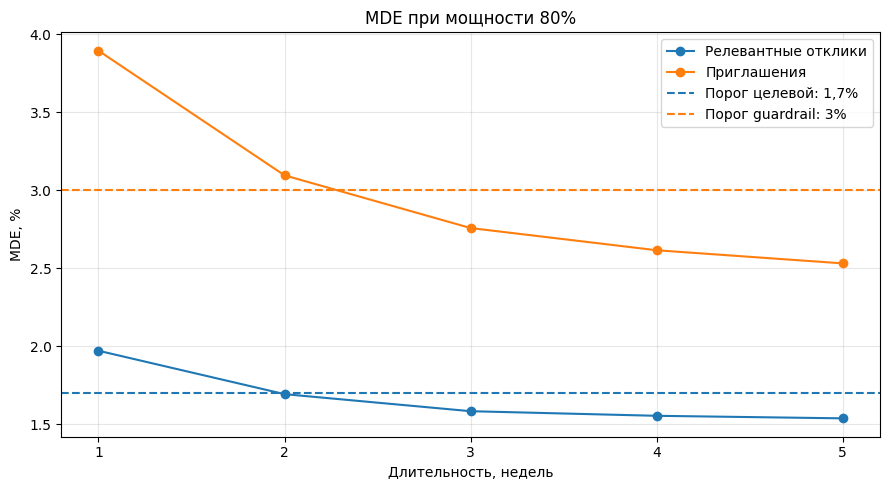

In [ ]:
import matplotlib.pyplot as plt

labels = {
    "relevant_responses_app": "Релевантные отклики",
    "invitations_app": "Приглашения"
}

fig, ax = plt.subplots(figsize=(9, 5))

for metric, label in labels.items():
    values = mde_table[mde_table["metric"] == metric]
    ax.plot(values["weeks"], values["mde_percentage"], marker="o", label=label)

ax.axhline(1.7, color="tab:blue", linestyle="--", label="Порог целевой: 1,7%")
ax.axhline(3, color="tab:orange", linestyle="--", label="Порог guardrail: 3%")
ax.set(xlabel="Длительность, недель", ylabel="MDE, %", title="MDE при мощности 80%")
ax.set_xticks(range(1, 6))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Вывод о форме графика: MDE обеих метрик снижается с увеличением длительности, но снижение постепенно замедляется. Каждая дополнительная неделя привлекает всё меньше новых уникальных соискателей. Одновременно меняются среднее и дисперсия накопленных метрик. После третьей недели дополнительный выигрыш в чувствительности становится небольшим.

# 5. A/A на истории

### Берём метрики соискателей за первые три недели выбранной истории. Тысячу раз случайно распределяем пользователей между двумя группами с вероятностью 50/50. Проверяем целевую метрику и оцениваем долю ложных срабатываний. Для воспроизводимости фиксируем seed.

In [17]:
from scipy.stats import ttest_ind, chisquare

week_starts = sorted(history["week_start"].unique())
period = history[history["week_start"].isin(week_starts[:3])]
aa_users = period.groupby("user_id")[metric_cols].sum()
aa_users = aa_users[aa_users["responses_app"] > 0].sort_index()

y = aa_users["relevant_responses_app"].to_numpy()
rng = np.random.default_rng(42)
p_values = []

for run in range(1000):
    group = rng.integers(0, 2, size=len(y))
    a = y[group == 0]
    b = y[group == 1]

    p_value = ttest_ind(a, b, equal_var=False, alternative="two-sided").pvalue
    p_values.append(p_value)

    if run == 0:
        first_group_sizes = np.array([len(a), len(b)])

p_values = np.array(p_values)

print("Количество A/A-запусков:", len(p_values))
print("Запусков с p < 0,05:", (p_values < 0.05).sum())
print(f"Доля значимых результатов: {(p_values < 0.05).mean():.2%}")

expected = np.array([len(y) / 2, len(y) / 2])
srm = chisquare(f_obs=first_group_sizes, f_exp=expected)

print("\nРазмеры групп первого разбиения:", first_group_sizes)
print(f"SRM: статистика = {srm.statistic:.4f}, p-value = {srm.pvalue:.6f}")

Количество A/A-запусков: 1000
Запусков с p < 0,05: 47
Доля значимых результатов: 4.70%

Размеры групп первого разбиения: [98955 99392]
SRM: статистика = 0.9628, p-value = 0.326482


### A/A на истории: провели 1 000 случайных разбиений соискателей за выбранные три недели. Целевую метрику сравнивали двусторонним t-тестом Уэлча. Доля запусков с p < 0,05 составила 4,7%, что близко к заданному уровню значимости 5%. Для первого разбиения проверка SRM не выявила нарушения пропорции 50/50: χ² = 0,9628, p = 0,326482. Для воспроизводимости использован seed = 42.